In [1]:
import os
import json
import shutil
import zipfile
import random
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image, ImageOps
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASSES = ["Glass", "Paper", "Plastic", "Metal"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

uploaded = files.upload()

if "image.zip" not in uploaded:
    raise ValueError("Upload your ZIP file with the exact name image.zip")

EXTRACT_DIR = "/content/waste_extracted"

if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)

os.makedirs(EXTRACT_DIR)

with zipfile.ZipFile("/content/image.zip", "r") as z:
    z.extractall(EXTRACT_DIR)

# Find the directory containing all four class folders
DATA_DIR = None

for root, dirs, _ in os.walk(EXTRACT_DIR):
    if all(cls in dirs for cls in CLASSES):
        DATA_DIR = root
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find Glass, Paper, Plastic, Metal folders. "
        "Check the ZIP folder structure."
    )

print("Dataset found:", DATA_DIR)

for cls in CLASSES:
    folder = os.path.join(DATA_DIR, cls)
    count = sum(
        f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
        for f in os.listdir(folder)
    )
    print(f"{cls}: {count} images")

Saving image.zip to image.zip
Dataset found: /content/waste_extracted/sample image
Glass: 20 images
Paper: 20 images
Plastic: 20 images
Metal: 20 images


In [2]:
BASE_DIR = "/content/waste_dataset"

if os.path.exists(BASE_DIR):
    shutil.rmtree(BASE_DIR)

ORIGINAL_DIR = os.path.join(BASE_DIR, "original")
SPLIT_DIR = os.path.join(BASE_DIR, "split")
AUG_DIR = os.path.join(BASE_DIR, "augmented_train")

for cls in CLASSES:
    os.makedirs(os.path.join(ORIGINAL_DIR, cls), exist_ok=True)

records = []
seen_hashes = set()
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for cls in CLASSES:
    source_folder = os.path.join(DATA_DIR, cls)

    for filename in sorted(os.listdir(source_folder)):
        if not filename.lower().endswith(extensions):
            continue

        source_path = os.path.join(source_folder, filename)

        try:
            with open(source_path, "rb") as f:
                digest = hashlib.md5(f.read()).hexdigest()

            if digest in seen_hashes:
                print("Duplicate skipped:", filename)
                continue

            with Image.open(source_path) as image:
                image = ImageOps.exif_transpose(image).convert("RGB")
                image = image.resize(IMG_SIZE)

                seen_hashes.add(digest)

                new_name = f"{cls}_{len(records):05d}.jpg"
                destination = os.path.join(
                    ORIGINAL_DIR, cls, new_name
                )

                image.save(destination, quality=95)
                records.append((destination, cls))

        except Exception as error:
            print("Unreadable image skipped:", filename, error)

df = pd.DataFrame(records, columns=["path", "label"])

print("\nCleaned dataset:")
print(df["label"].value_counts().reindex(CLASSES, fill_value=0))

if df.empty or any(
    (df["label"] == cls).sum() < 7 for cls in CLASSES
):
    raise ValueError(
        "Each class needs at least 7 valid original images "
        "for this stratified split. Collect more images."
    )

train_df, remaining_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_df["label"]
)

for split_name, split_df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:
    for _, row in split_df.iterrows():
        destination = os.path.join(
            SPLIT_DIR, split_name, row["label"],
            os.path.basename(row["path"])
        )

        os.makedirs(os.path.dirname(destination), exist_ok=True)
        shutil.copy2(row["path"], destination)

print("\nOriginal image split:")
for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"{name}: {len(part)} images")

print("\nDataset split saved at:", SPLIT_DIR)


Cleaned dataset:
label
Glass      20
Paper      20
Plastic    20
Metal      20
Name: count, dtype: int64

Original image split:
Training: 56 images
Validation: 12 images
Testing: 12 images

Dataset split saved at: /content/waste_dataset/split


In [3]:
from PIL import ImageEnhance

AUGMENTATIONS_PER_IMAGE = 4

for cls in CLASSES:
    source_folder = os.path.join(SPLIT_DIR, "train", cls)
    output_folder = os.path.join(AUG_DIR, cls)

    os.makedirs(output_folder, exist_ok=True)

    for filename in os.listdir(source_folder):
        source_path = os.path.join(source_folder, filename)

        with Image.open(source_path) as image:
            original = image.convert("RGB")

        # Keep the original training image
        shutil.copy2(
            source_path,
            os.path.join(output_folder, filename)
        )

        stem = os.path.splitext(filename)[0]

        for i in range(AUGMENTATIONS_PER_IMAGE):
            augmented = original.copy()

            if random.random() < 0.5:
                augmented = ImageOps.mirror(augmented)

            augmented = augmented.rotate(
                random.uniform(-15, 15),
                resample=Image.Resampling.BILINEAR,
                fillcolor=(255, 255, 255)
            )

            augmented = ImageEnhance.Brightness(augmented).enhance(
                random.uniform(0.80, 1.20)
            )

            augmented = ImageEnhance.Contrast(augmented).enhance(
                random.uniform(0.85, 1.15)
            )

            augmented.save(
                os.path.join(
                    output_folder, f"{stem}_aug_{i+1}.jpg"
                ),
                quality=95
            )

print("Augmented dataset saved at:", AUG_DIR)

for cls in CLASSES:
    count = len([
        f for f in os.listdir(os.path.join(AUG_DIR, cls))
        if f.lower().endswith(extensions)
    ])
    print(f"{cls}: {count} training images after augmentation")

Augmented dataset saved at: /content/waste_dataset/augmented_train
Glass: 70 training images after augmentation
Paper: 70 training images after augmentation
Plastic: 70 training images after augmentation
Metal: 70 training images after augmentation


In [4]:
def load_dataset(folder, shuffle=False):
    return tf.keras.utils.image_dataset_from_directory(
        folder,
        class_names=CLASSES,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED
    ).prefetch(tf.data.AUTOTUNE)

train_ds = load_dataset(AUG_DIR, shuffle=True)
val_ds = load_dataset(os.path.join(SPLIT_DIR, "val"))
test_ds = load_dataset(os.path.join(SPLIT_DIR, "test"))

print("Class mapping:", dict(enumerate(CLASSES)))

Found 280 files belonging to 4 classes.
Found 12 files belonging to 4 classes.
Found 12 files belonging to 4 classes.
Class mapping: {0: 'Glass', 1: 'Paper', 2: 'Plastic', 3: 'Metal'}


In [5]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# MobileNetV2 preprocessing: pixel values 0–255 to -1–1
x = layers.Rescaling(1.0 / 127.5, offset=-1)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.20)(x)

outputs = layers.Dense(
    len(CLASSES), activation="softmax"
)(x)

model = Model(inputs, outputs, name="WasteMobileNetV2")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "WasteMobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,228 (8.93 MB)

 Trainable params: 82,244 (321.27 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
checkpoint_path = "/content/best_waste_model.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

# Load the checkpoint with the best validation loss
model = tf.keras.models.load_model(checkpoint_path)

print("Best model loaded successfully.")

Epoch 1/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.4051 - loss: 1.3893
Epoch 1: val_loss improved from None to 0.85316, saving model to /content/best_waste_model.keras

Epoch 1: finished saving model to /content/best_waste_model.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 637ms/step - accuracy: 0.5321 - loss: 1.1098 - val_accuracy: 0.7500 - val_loss: 0.8532 - learning_rate: 5.0000e-04
Epoch 2/20
15/18 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9005 - loss: 0.4182
Epoch 2: val_loss improved from 0.85316 to 0.62593, saving model to /content/best_waste_model.keras

Epoch 2: finished saving model to /content/best_waste_model.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.9179 - loss: 0.3733 - val_accuracy: 0.8333 - val_loss: 0.6259 - learning_rate: 5.0000e-04
Epoch 3/20
16/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9792 - loss: 0.1763
Epoch 3: val_loss improved from 0.62593 to 0.61593, saving model to /content/best_waste_model.keras

Epoch 3: finished savi

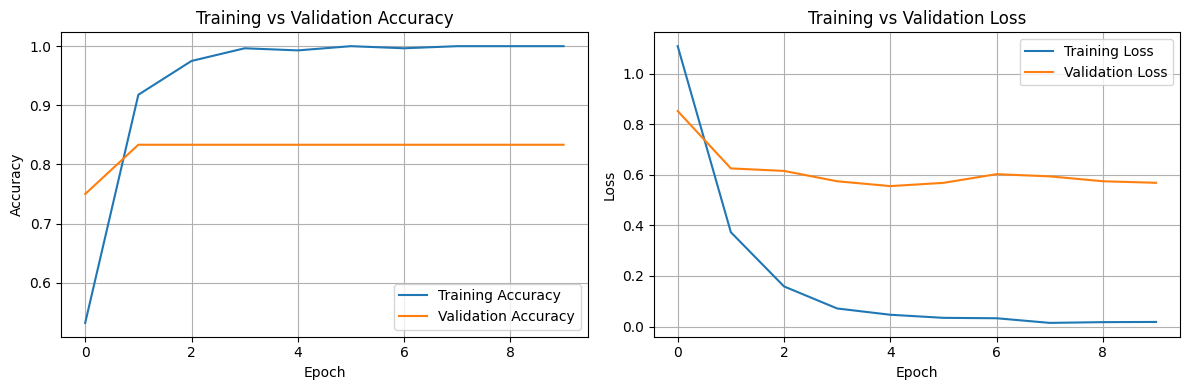

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("/content/training_graphs.png", dpi=150)
plt.show()

In [8]:
for name, dataset in [
    ("Validation", val_ds),
    ("Test", test_ds)
]:
    loss, accuracy = model.evaluate(dataset, verbose=0)

    print(f"\n{name} Results")
    print(f"Loss: {loss:.4f}")
    print(f"Accuracy: {accuracy * 100:.2f}%")


Validation Results
Loss: 0.5558
Accuracy: 83.33%

Test Results
Loss: 0.0953
Accuracy: 100.00%


Correct predictions: 12 / 12
Test accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

       Glass       1.00      1.00      1.00         3
       Paper       1.00      1.00      1.00         3
     Plastic       1.00      1.00      1.00         3
       Metal       1.00      1.00      1.00         3

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



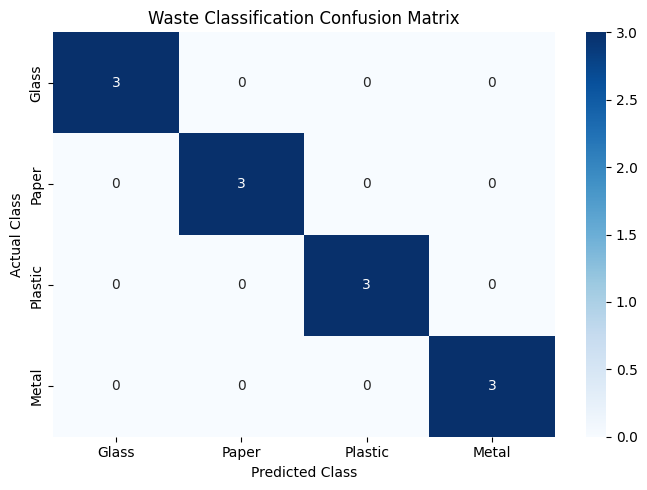

In [10]:
import seaborn as sns
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Correct predictions:", np.sum(y_true == y_pred), "/", len(y_true))
print(f"Test accuracy: {np.mean(y_true == y_pred) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(len(CLASSES)))
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("Waste Classification Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=150)
plt.show()

In [12]:
# Save final model
model.save("/content/smart_waste_classifier.keras")

# Prepare dataset export
EXPORT_DIR = "/content/waste_dataset_export"

if os.path.exists(EXPORT_DIR):
    shutil.rmtree(EXPORT_DIR)

os.makedirs(EXPORT_DIR)

shutil.copytree(
    SPLIT_DIR,
    os.path.join(EXPORT_DIR, "split")
)

shutil.copytree(
    AUG_DIR,
    os.path.join(EXPORT_DIR, "augmented_train")
)

# Save experiment information
metadata = {
    "classes": CLASSES,
    "image_size": list(IMG_SIZE),
    "split_ratio": "70:15:15",
    "augmentation_copies_per_training_image": AUGMENTATIONS_PER_IMAGE,
    "model": "MobileNetV2 transfer learning",
    "validation_accuracy": float(model.evaluate(val_ds, verbose=0)[1]),
    "test_accuracy": float(model.evaluate(test_ds, verbose=0)[1])
}

with open(os.path.join(EXPORT_DIR, "metadata.json"), "w") as f:
    json.dump(metadata, f, indent=4)

# ZIP the prepared dataset
dataset_zip = shutil.make_archive(
    "/content/smart_waste_dataset",
    "zip",
    EXPORT_DIR
)

print("Saved files:")
print(dataset_zip)
print("/content/smart_waste_classifier.keras")
print("/content/training_graphs.png")
print("/content/confusion_matrix.png")

files.download(dataset_zip)
files.download("/content/smart_waste_classifier.keras")
files.download("/content/training_graphs.png")
files.download("/content/confusion_matrix.png")

Saved files:
/content/smart_waste_dataset.zip
/content/smart_waste_classifier.keras
/content/training_graphs.png
/content/confusion_matrix.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>